<a href="https://colab.research.google.com/github/Dania-Yasir/CodeAlpha_Handwritten_Character_Recognition/blob/main/notebooks/EMNIST_Character_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow_datasets as tfds
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt



In [2]:
%pip install -q importlib-resources

In [3]:
import importlib_resources

print("Library installed successfully!")

Library installed successfully!


In [4]:
# Load EMNIST Balanced Dataset
train_ds, test_ds = tfds.load(
    'emnist/balanced',
    split=['train', 'test'],
    as_supervised=True
)

print("EMNIST Balanced dataset loaded successfully!")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/balanced/incomplete.LAMZR0_3.1.0/emnist-train.tfrecord-[0-9][0-9][0…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/balanced/incomplete.LAMZR0_3.1.0/emnist-test.tfrecord-[0-9][0-9][0-…

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/balanced/3.1.0. Subsequent calls will reuse this data.
EMNIST Balanced dataset loaded successfully!


In [5]:
# Explore EMNIST Dataset

print("Training images:", train_ds.cardinality().numpy())
print("Testing images:", test_ds.cardinality().numpy())

# Get one sample
for image, label in train_ds.take(1):
    print("Image shape:", image.shape)
    print("Label:", label.numpy())
    print("Pixel data type:", image.dtype)

Training images: 112800
Testing images: 18800
Image shape: (28, 28, 1)
Label: 31
Pixel data type: <dtype: 'uint8'>


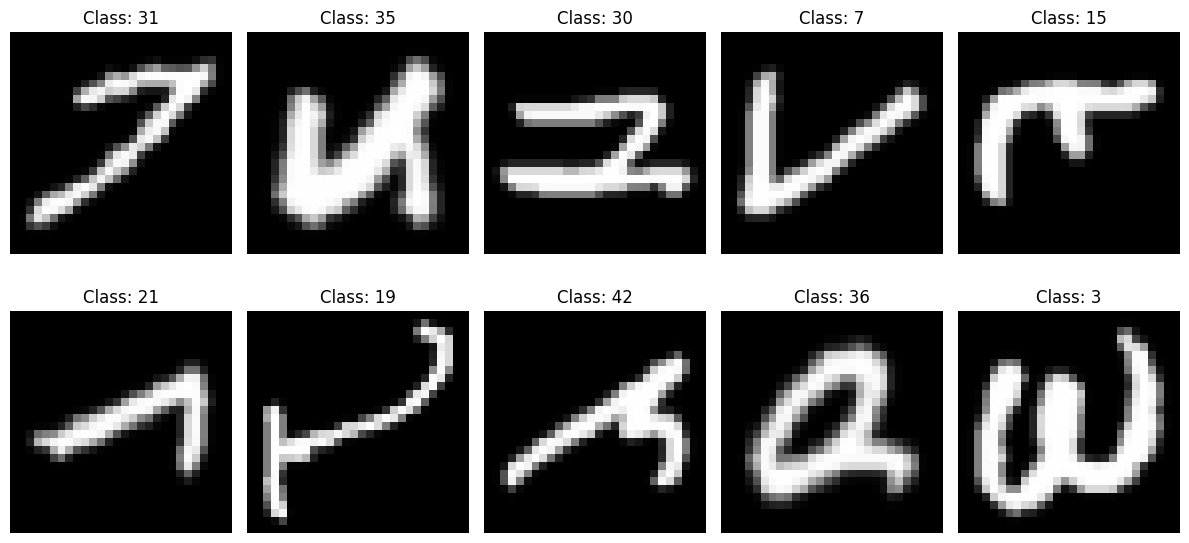

In [6]:
# Display EMNIST sample images

plt.figure(figsize=(12, 6))

for i, (image, label) in enumerate(train_ds.take(10)):

    plt.subplot(2, 5, i + 1)

    plt.imshow(image.numpy().squeeze(), cmap='gray')

    plt.title(f"Class: {label.numpy()}")

    plt.axis('off')

plt.tight_layout()
plt.show()

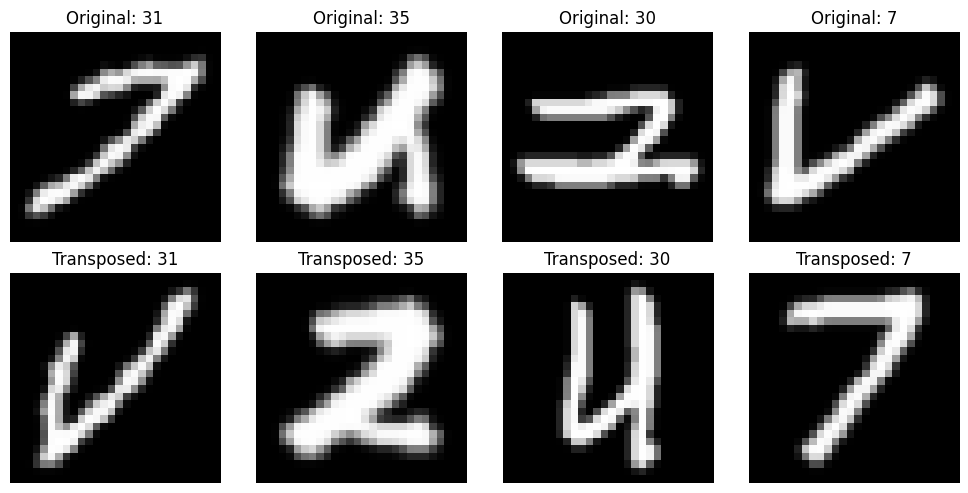

In [7]:
# Compare original and transposed EMNIST images

plt.figure(figsize=(10, 5))

for i, (image, label) in enumerate(train_ds.take(4)):

    original = image.numpy().squeeze()

    corrected = original.T

    # Original image
    plt.subplot(2, 4, i + 1)
    plt.imshow(original, cmap='gray')
    plt.title(f"Original: {label.numpy()}")
    plt.axis('off')

    # Transposed image
    plt.subplot(2, 4, i + 5)
    plt.imshow(corrected, cmap='gray')
    plt.title(f"Transposed: {label.numpy()}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
# Get EMNIST dataset information

info = tfds.builder('emnist/balanced').info

label_names = info.features['label'].names

print("Number of classes:", len(label_names))

for i, name in enumerate(label_names):
    print(f"Class {i}: {name}")

Number of classes: 47
Class 0: 0
Class 1: 1
Class 2: 2
Class 3: 3
Class 4: 4
Class 5: 5
Class 6: 6
Class 7: 7
Class 8: 8
Class 9: 9
Class 10: 10
Class 11: 11
Class 12: 12
Class 13: 13
Class 14: 14
Class 15: 15
Class 16: 16
Class 17: 17
Class 18: 18
Class 19: 19
Class 20: 20
Class 21: 21
Class 22: 22
Class 23: 23
Class 24: 24
Class 25: 25
Class 26: 26
Class 27: 27
Class 28: 28
Class 29: 29
Class 30: 30
Class 31: 31
Class 32: 32
Class 33: 33
Class 34: 34
Class 35: 35
Class 36: 36
Class 37: 37
Class 38: 38
Class 39: 39
Class 40: 40
Class 41: 41
Class 42: 42
Class 43: 43
Class 44: 44
Class 45: 45
Class 46: 46


In [9]:
# Step 19: EMNIST Data Preprocessing

AUTOTUNE = tf.data.AUTOTUNE

def preprocess_image(image, label):

    # Correct image orientation
    image = tf.transpose(image, perm=[1, 0, 2])

    # Convert pixels to float32 and normalize
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [10]:
# Prepare training dataset

train_prepared = (
    train_ds
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .shuffle(10000)
    .batch(64)
    .prefetch(AUTOTUNE)
)

# Prepare testing dataset

test_prepared = (
    test_ds
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(64)
    .prefetch(AUTOTUNE)
)

print("EMNIST preprocessing completed successfully!")

EMNIST preprocessing completed successfully!


In [11]:
# Step 20: Train / Validation Split

TRAIN_SIZE = 101520
VAL_SIZE = 11280

# Split original training dataset
train_raw = train_ds.take(TRAIN_SIZE)
val_raw = train_ds.skip(TRAIN_SIZE)

# Prepare Training Dataset
train_final = (
    train_raw
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .shuffle(10000, seed=42)
    .batch(64)
    .prefetch(AUTOTUNE)
)

# Prepare Validation Dataset
val_final = (
    val_raw
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(64)
    .prefetch(AUTOTUNE)
)

# Prepare Testing Dataset
test_final = (
    test_ds
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(64)
    .prefetch(AUTOTUNE)
)

print("Training samples:", train_raw.cardinality().numpy())
print("Validation samples:", val_raw.cardinality().numpy())
print("Testing samples:", test_ds.cardinality().numpy())

Training samples: 101520
Validation samples: 11280
Testing samples: 18800


In [12]:
# Step 20.1: Load EMNIST Dataset

import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

# Load training dataset
train_ds = tfds.load(
    'emnist/balanced',
    split='train',
    as_supervised=True,
    shuffle_files=False
)

# Load testing dataset
test_ds = tfds.load(
    'emnist/balanced',
    split='test',
    as_supervised=True,
    shuffle_files=False
)

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [13]:
# Step 20.2: Split Dataset

TRAIN_SIZE = 101520

# Split training and validation
train_raw = train_ds.take(TRAIN_SIZE)
val_raw = train_ds.skip(TRAIN_SIZE)

print("Training samples:", train_raw.cardinality().numpy())
print("Validation samples:", val_raw.cardinality().numpy())
print("Testing samples:", test_ds.cardinality().numpy())

Training samples: 101520
Validation samples: 11280
Testing samples: 18800


In [14]:
# Step 20.3: Preprocess EMNIST Images

AUTOTUNE = tf.data.AUTOTUNE

def preprocess_image(image, label):

    # Correct image orientation
    image = tf.transpose(image, perm=[1, 0, 2])

    # Normalize pixels
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


# Training Dataset
train_final = (
    train_raw
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .shuffle(10000, seed=42)
    .batch(64)
    .prefetch(AUTOTUNE)
)

# Validation Dataset
val_final = (
    val_raw
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(64)
    .prefetch(AUTOTUNE)
)

# Testing Dataset
test_final = (
    test_ds
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(64)
    .prefetch(AUTOTUNE)
)

print("Data preprocessing completed successfully!")

Data preprocessing completed successfully!


In [15]:
# Step 21.1: Build EMNIST CNN Model

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

emnist_model = Sequential([

    # Input Layer
    Input(shape=(28, 28, 1)),

    # First Convolutional Block
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Second Convolutional Block
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Flatten Layer
    Flatten(),

    # Fully Connected Layer
    Dense(128, activation='relu'),

    # Dropout Layer
    Dropout(0.3),

    # Output Layer
    Dense(47, activation='softmax')

])

# Display model architecture
emnist_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 47)             │         6,063 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 229,807 (897.68 KB)

 Trainable params: 229,807 (897.68 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Step 21.2: Compile EMNIST CNN Model

emnist_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("EMNIST CNN model compiled successfully!")

EMNIST CNN model compiled successfully!


In [17]:
# Step 22.1: Training Callbacks

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

model_checkpoint = ModelCheckpoint(
    filepath='best_emnist_model.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

print("Training callbacks are ready!")

Training callbacks are ready!


In [18]:
# Step 22.2: Train EMNIST CNN Model

emnist_history = emnist_model.fit(
    train_final,
    validation_data=val_final,
    epochs=15,
    callbacks=[
        early_stopping,
        model_checkpoint
    ]
)

print("EMNIST model training completed!")

Epoch 1/15
1587/1587 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5578 - loss: 1.5565
Epoch 1: val_loss improved from None to 0.48253, saving model to best_emnist_model.keras

Epoch 1: finished saving model to best_emnist_model.keras
1587/1587 ━━━━━━━━━━━━━━━━━━━━ 36s 17ms/step - accuracy: 0.6977 - loss: 0.9952 - val_accuracy: 0.8395 - val_loss: 0.4825
Epoch 2/15
1578/1587 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8058 - loss: 0.5878
Epoch 2: val_loss improved from 0.48253 to 0.40605, saving model to best_emnist_model.keras

Epoch 2: finished saving model to best_emnist_model.keras
1587/1587 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8142 - loss: 0.5573 - val_accuracy: 0.8578 - val_loss: 0.4060
Epoch 3/15
1577/1587 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8352 - loss: 0.4928
Epoch 3: val_loss improved from 0.40605 to 0.37776, saving model to best_emnist_model.keras

Epoch 3: finished saving model to best_emnist_model.keras
1587/1587 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step -

In [21]:
# Save trained model
emnist_model.save("emnist_model.keras")

# Download model
from google.colab import files
files.download("emnist_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
# Step 23: Evaluate EMNIST CNN Model

test_loss, test_accuracy = emnist_model.evaluate(
    test_final,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

294/294 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8735 - loss: 0.3669
Test Accuracy: 87.35%
Test Loss: 0.3669


In [23]:
# Step 24.1: Get EMNIST Predictions

import numpy as np

# Predict all test images
predictions = emnist_model.predict(test_final)

# Convert probabilities into class numbers
y_pred_emnist = np.argmax(predictions, axis=1)

# Extract true labels
y_true_emnist = np.concatenate([
    labels.numpy()
    for images, labels in test_final
])

print("True labels:", y_true_emnist.shape)
print("Predicted labels:", y_pred_emnist.shape)

294/294 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step
True labels: (18800,)
Predicted labels: (18800,)


In [24]:
# Step 24.2: Classification Report

from sklearn.metrics import classification_report

report = classification_report(
    y_true_emnist,
    y_pred_emnist,
    digits=4
)

print("EMNIST Classification Report")
print(report)

EMNIST Classification Report
              precision    recall  f1-score   support

           0     0.6564    0.6925    0.6740       400
           1     0.5383    0.6675    0.5960       400
           2     0.9002    0.9025    0.9014       400
           3     0.9949    0.9775    0.9861       400
           4     0.9173    0.9425    0.9297       400
           5     0.9037    0.9150    0.9093       400
           6     0.9439    0.9250    0.9343       400
           7     0.9682    0.9900    0.9790       400
           8     0.8799    0.9525    0.9148       400
           9     0.6991    0.7725    0.7340       400
          10     0.9488    0.9725    0.9605       400
          11     0.9715    0.9375    0.9542       400
          12     0.9610    0.9250    0.9427       400
          13     0.8812    0.9275    0.9038       400
          14     0.9679    0.9800    0.9739       400
          15     0.6169    0.6925    0.6525       400
          16     0.9446    0.9375    0.9410       40

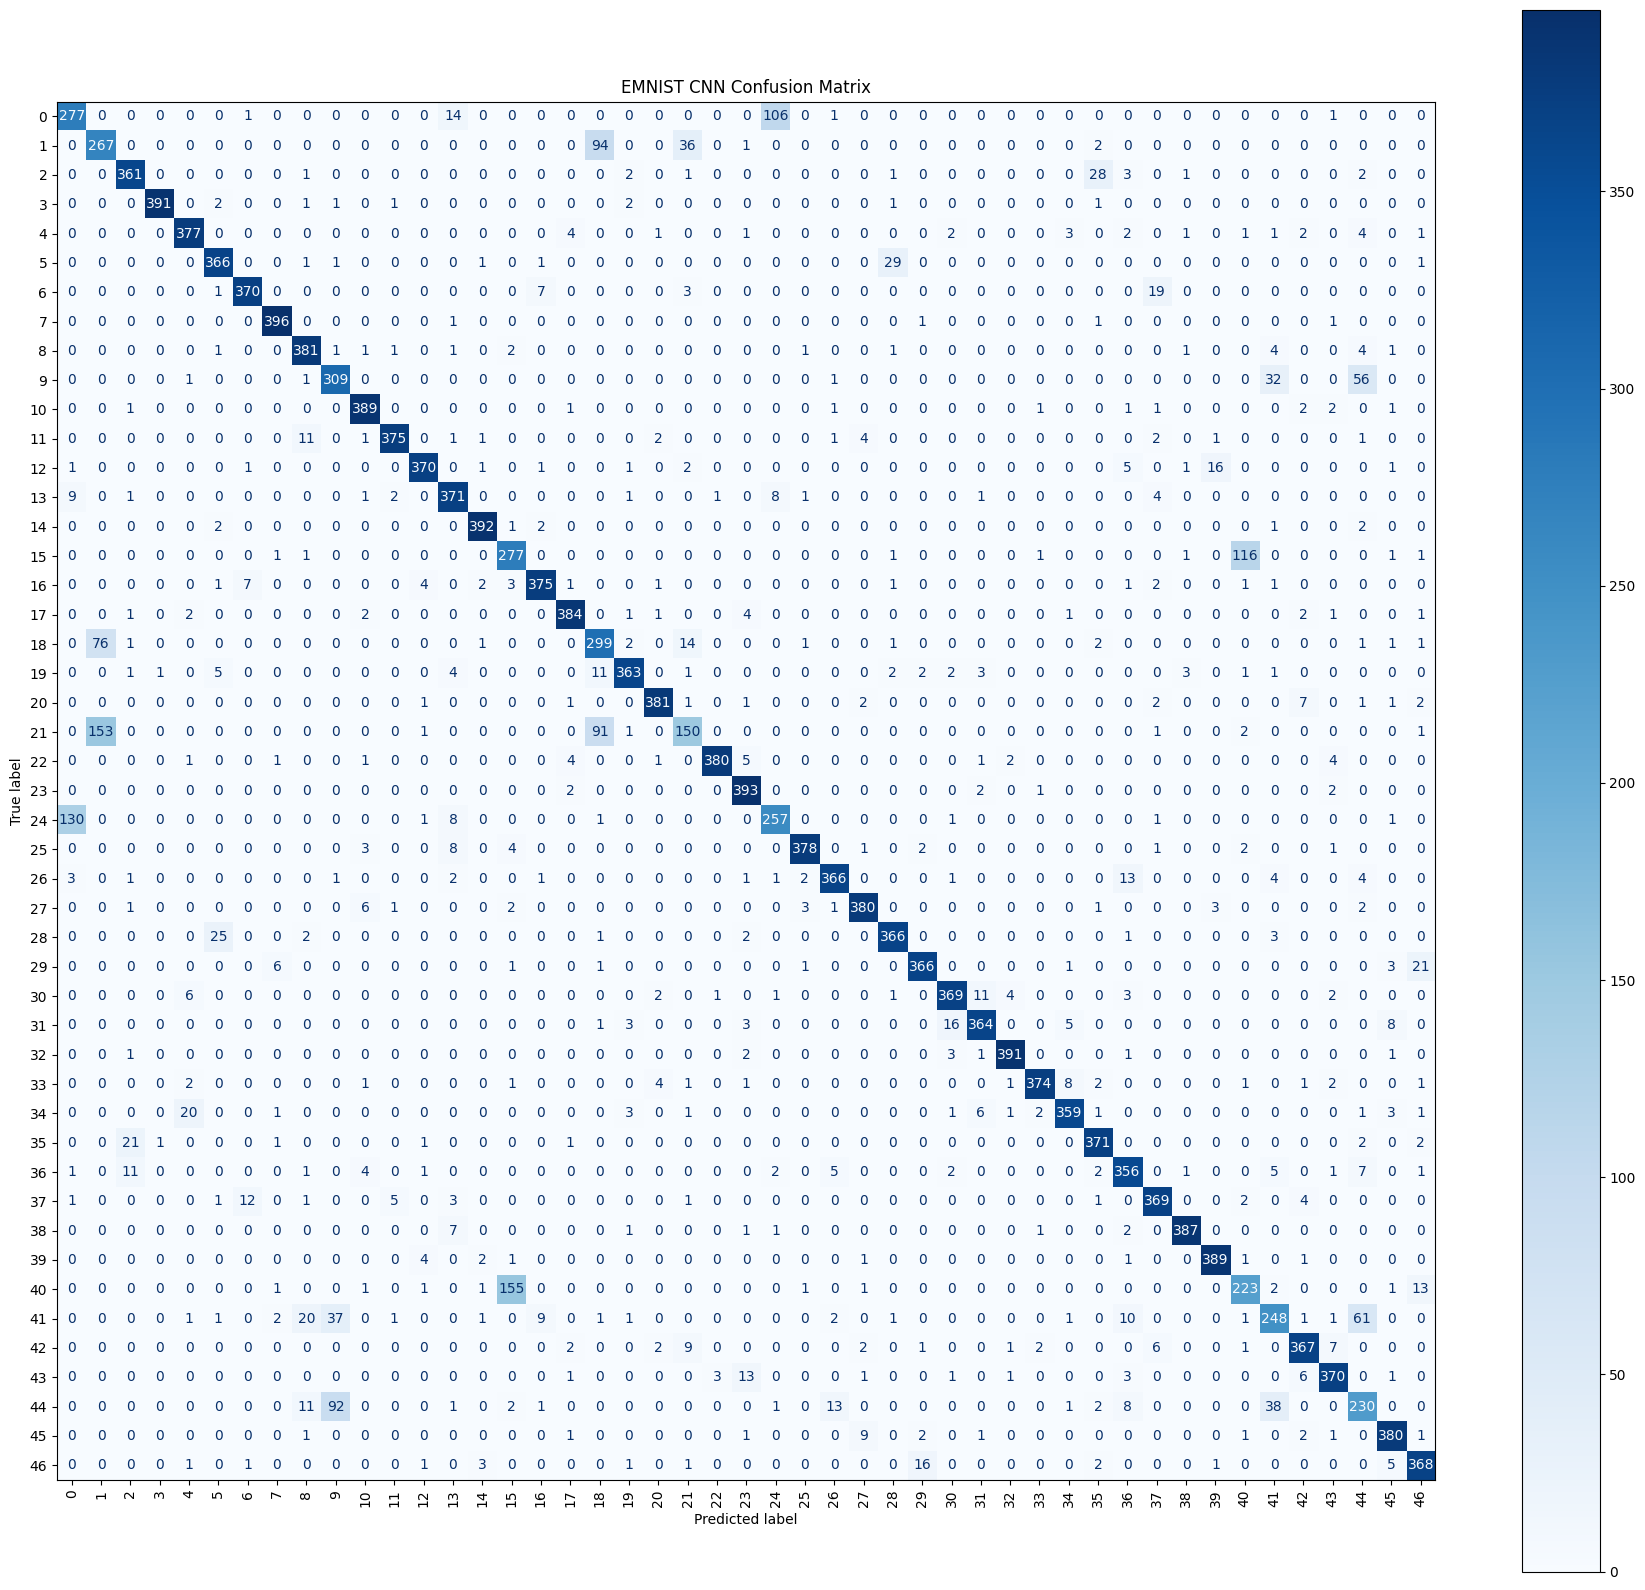

In [25]:
# Step 24.3: EMNIST Confusion Matrix

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true_emnist,
    y_pred_emnist
)

fig, ax = plt.subplots(figsize=(18, 16))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(47)
)

disp.plot(
    cmap='Blues',
    ax=ax,
    values_format='d',
    colorbar=True
)

plt.title("EMNIST CNN Confusion Matrix")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig(
    'emnist_confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [26]:
# Step 25: Find Most Common Classification Errors

from sklearn.metrics import confusion_matrix
import numpy as np

# Create confusion matrix
cm = confusion_matrix(
    y_true_emnist,
    y_pred_emnist,
    labels=np.arange(47)
)

# Copy matrix to keep original unchanged
cm_errors = cm.copy()

# Remove correct predictions (diagonal)
np.fill_diagonal(cm_errors, 0)

# Find top 10 confusion pairs
top_indices = np.argsort(
    cm_errors.ravel()
)[-10:][::-1]

print("Top 10 Most Common Classification Errors:\n")

for index in top_indices:

    true_class, predicted_class = np.unravel_index(
        index,
        cm_errors.shape
    )

    error_count = cm_errors[
        true_class,
        predicted_class
    ]

    print(
        f"True Class: {true_class} | "
        f"Predicted Class: {predicted_class} | "
        f"Errors: {error_count}"
    )

Top 10 Most Common Classification Errors:

True Class: 40 | Predicted Class: 15 | Errors: 155
True Class: 21 | Predicted Class: 1 | Errors: 153
True Class: 24 | Predicted Class: 0 | Errors: 130
True Class: 15 | Predicted Class: 40 | Errors: 116
True Class: 0 | Predicted Class: 24 | Errors: 106
True Class: 1 | Predicted Class: 18 | Errors: 94
True Class: 44 | Predicted Class: 9 | Errors: 92
True Class: 21 | Predicted Class: 18 | Errors: 91
True Class: 18 | Predicted Class: 1 | Errors: 76
True Class: 41 | Predicted Class: 44 | Errors: 61


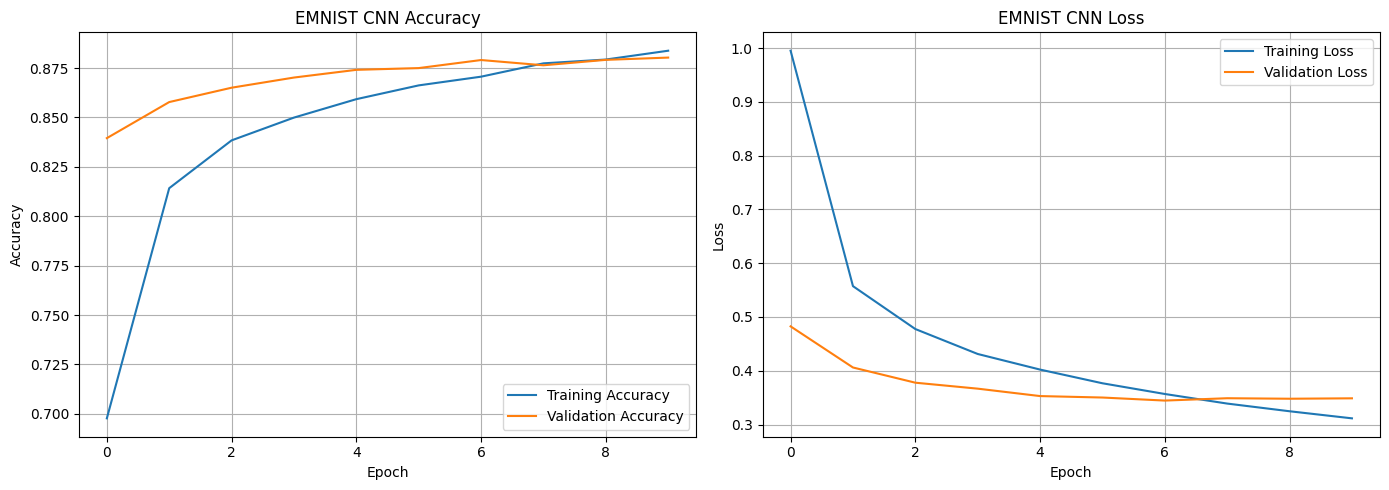

In [27]:
# Step 26: EMNIST Training Curves

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(
    emnist_history.history['accuracy'],
    label='Training Accuracy'
)

axes[0].plot(
    emnist_history.history['val_accuracy'],
    label='Validation Accuracy'
)

axes[0].set_title('EMNIST CNN Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(
    emnist_history.history['loss'],
    label='Training Loss'
)

axes[1].plot(
    emnist_history.history['val_loss'],
    label='Validation Loss'
)

axes[1].set_title('EMNIST CNN Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    'emnist_training_curves.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [28]:
# Step 27: Load official EMNIST Balanced label mapping

import requests

mapping_url = (
    "https://biometrics.nist.gov/cs_links/EMNIST/"
    "gzip.zip"
)

response = requests.get(mapping_url, timeout=60)

print("Download status:", response.status_code)
print("File size:", len(response.content), "bytes")

Download status: 200
File size: 561753746 bytes


In [29]:
# EMNIST Balanced class mapping

balanced_characters = (
    "0123456789"
    "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
    "abdefghnqrt"
)

print("Number of mapped characters:", len(balanced_characters))

for i, char in enumerate(balanced_characters):
    print(f"Class {i}: {char}")

Number of mapped characters: 47
Class 0: 0
Class 1: 1
Class 2: 2
Class 3: 3
Class 4: 4
Class 5: 5
Class 6: 6
Class 7: 7
Class 8: 8
Class 9: 9
Class 10: A
Class 11: B
Class 12: C
Class 13: D
Class 14: E
Class 15: F
Class 16: G
Class 17: H
Class 18: I
Class 19: J
Class 20: K
Class 21: L
Class 22: M
Class 23: N
Class 24: O
Class 25: P
Class 26: Q
Class 27: R
Class 28: S
Class 29: T
Class 30: U
Class 31: V
Class 32: W
Class 33: X
Class 34: Y
Class 35: Z
Class 36: a
Class 37: b
Class 38: d
Class 39: e
Class 40: f
Class 41: g
Class 42: h
Class 43: n
Class 44: q
Class 45: r
Class 46: t


Total incorrect predictions: 2378


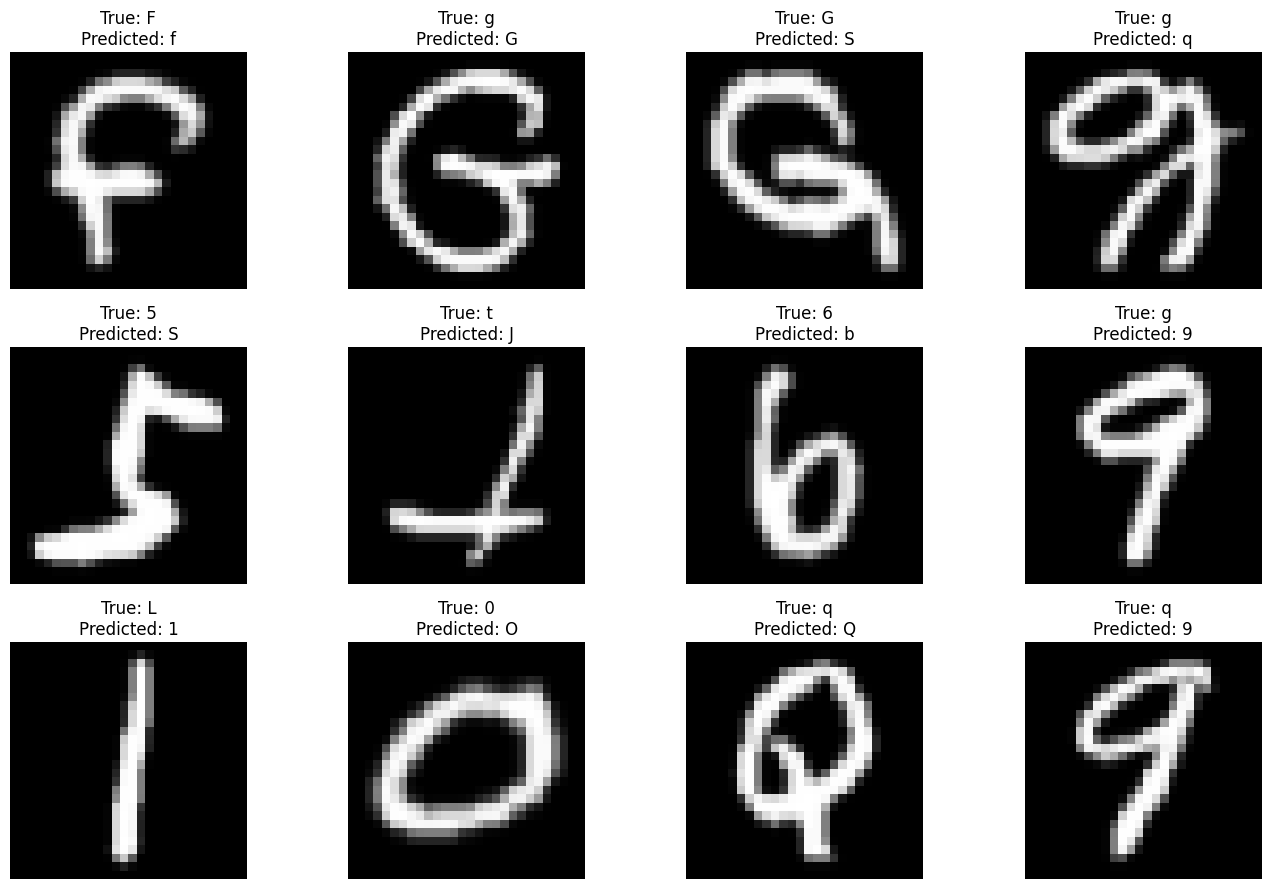

In [30]:
# Step 28: Visual Error Analysis

import numpy as np
import matplotlib.pyplot as plt

# Character mapping
balanced_characters = (
    "0123456789"
    "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
    "abdefghnqrt"
)

# Find incorrect predictions
incorrect_indices = np.where(
    y_true_emnist != y_pred_emnist
)[0]

print("Total incorrect predictions:", len(incorrect_indices))

# Get test images
test_images = np.concatenate([
    images.numpy()
    for images, labels in test_final
])

# Display first 12 incorrect predictions
plt.figure(figsize=(14, 9))

for i, index in enumerate(incorrect_indices[:12]):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        test_images[index].squeeze(),
        cmap='gray'
    )

    true_char = balanced_characters[y_true_emnist[index]]
    pred_char = balanced_characters[y_pred_emnist[index]]

    plt.title(
        f"True: {true_char}\n"
        f"Predicted: {pred_char}"
    )

    plt.axis('off')

plt.tight_layout()

plt.savefig(
    'emnist_error_analysis.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [31]:
# Step 29.1: Upload Your Handwritten Image

from google.colab import files

uploaded = files.upload()

Saving Gemini_Generated_Image_cdkrajcdkrajcdkr.jpg to Gemini_Generated_Image_cdkrajcdkrajcdkr.jpg


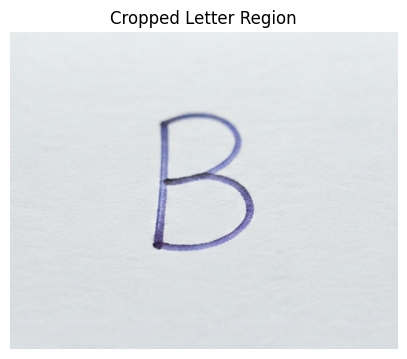

In [37]:
from PIL import Image, ImageOps, ImageEnhance
import numpy as np
import matplotlib.pyplot as plt

# Load original image
filename = next(iter(uploaded))
original = Image.open(filename).convert("RGB")

# Get image dimensions
width, height = original.size

# Crop central region containing the letter
left = int(width * 0.30)
right = int(width * 0.70)
top = int(height * 0.20)
bottom = int(height * 0.80)

cropped = original.crop((left, top, right, bottom))

# Display cropped region
plt.figure(figsize=(5, 5))
plt.imshow(cropped)
plt.title("Cropped Letter Region")
plt.axis("off")
plt.show()

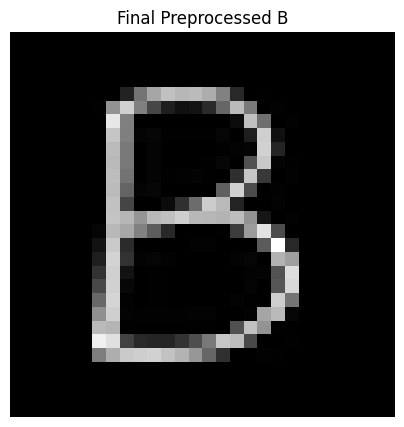

In [38]:
# Convert to grayscale
gray = cropped.convert("L")

# Invert colors
inverted = ImageOps.invert(gray)

# Increase contrast
enhancer = ImageEnhance.Contrast(inverted)
inverted = enhancer.enhance(3.0)

# Remove weak background pixels
arr = np.array(inverted)
arr[arr < 100] = 0

# Crop to character bounding box
mask = Image.fromarray(arr)
bbox = mask.getbbox()

if bbox is None:
    raise ValueError("No character detected!")

letter = mask.crop(bbox)

# Resize while preserving aspect ratio
letter.thumbnail((20, 20), Image.Resampling.LANCZOS)

# Create 28x28 black canvas
canvas = Image.new("L", (28, 28), 0)

x = (28 - letter.width) // 2
y = (28 - letter.height) // 2

canvas.paste(letter, (x, y))

# Prepare image for CNN
img_array = np.array(canvas, dtype=np.float32) / 255.0
img_array = img_array.reshape(1, 28, 28, 1)

# Display final image
plt.figure(figsize=(5, 5))
plt.imshow(canvas, cmap="gray")
plt.title("Final Preprocessed B")
plt.axis("off")
plt.show()

In [39]:
# Step 29.3: Predict Custom Handwriting

# Predict probabilities
prediction = emnist_model.predict(img_array)

# Get predicted class
predicted_class = np.argmax(prediction)

# Convert class number into character
predicted_character = balanced_characters[predicted_class]

# Get confidence
confidence = np.max(prediction) * 100

print("Predicted Class:", predicted_class)
print("Predicted Character:", predicted_character)
print(f"Model Confidence: {confidence:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Predicted Class: 11
Predicted Character: B
Model Confidence: 93.07%


In [40]:
# Save final EMNIST model

emnist_model.save("emnist_final_model.keras")

from google.colab import files
files.download("emnist_final_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>